# Get distrubution of potential pia flights for ladd

In [4]:
from pia.ladd_aircraft_pia_candidates import get_ladd_pia_candidates
from data_engineering.flights.flight_type import get_flights
from datetime import date
import polars as pl
df = get_flights(date(2025, 1, 1), end_date = date(2026, 1, 1))
df = df.filter((pl.col("ladd")) & (pl.col("category") != "A7"))
df = df.unique(subset=["icao", "takeoff_time"])
total_count = df.get_column("icao").n_unique()
print(total_count)
candidates = get_ladd_pia_candidates(df)
# print percentage
candidates

17923


{'c045a5': {'potential_pia_flight_count': 8,
  'total_count': 239,
  'ratio': 0.03347280334728033},
 'a94cc2': {'potential_pia_flight_count': 125,
  'total_count': 279,
  'ratio': 0.44802867383512546},
 'c001ef': {'potential_pia_flight_count': 0, 'total_count': 24, 'ratio': 0.0},
 '1427dc': {'potential_pia_flight_count': 0, 'total_count': 13, 'ratio': 0.0},
 'a338db': {'potential_pia_flight_count': 16,
  'total_count': 153,
  'ratio': 0.10457516339869281},
 'add3d1': {'potential_pia_flight_count': 7,
  'total_count': 51,
  'ratio': 0.13725490196078433},
 'aa0e0f': {'potential_pia_flight_count': 2,
  'total_count': 14,
  'ratio': 0.14285714285714285},
 'a31cff': {'potential_pia_flight_count': 40,
  'total_count': 52,
  'ratio': 0.7692307692307693},
 'a6c4db': {'potential_pia_flight_count': 47,
  'total_count': 64,
  'ratio': 0.734375},
 'a82ddd': {'potential_pia_flight_count': 43,
  'total_count': 65,
  'ratio': 0.6615384615384615},
 'a5c135': {'potential_pia_flight_count': 20,
  'total

In [7]:
import pickle
from data_engineering.utils import OUTPUT_DIR
with open(f"{OUTPUT_DIR}/tmp/ladd_pia_candidates.pkl", "wb") as f:
    pickle.dump(candidates, f)

## Candidate distribution

aircraft_count,candidate_count,median_potential_pia_flights,median_ratio
u32,u32,f64,f64
17923,8217,9.0,0.188235


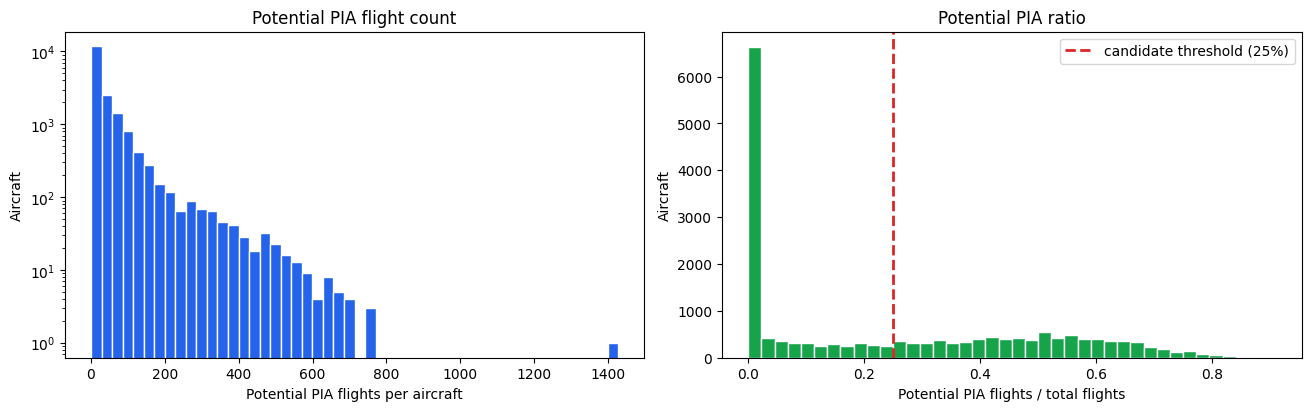

In [5]:
import matplotlib.pyplot as plt

candidate_distribution = pl.DataFrame(
    [{"icao": icao, **stats} for icao, stats in candidates.items()]
).sort("ratio", descending=True)

candidate_threshold = 0.25
candidate_summary = candidate_distribution.select(
    pl.len().alias("aircraft_count"),
    (pl.col("ratio") >= candidate_threshold).sum().alias("candidate_count"),
    pl.col("potential_pia_flight_count").median().alias("median_potential_pia_flights"),
    pl.col("ratio").median().alias("median_ratio"),
)
display(candidate_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)

axes[0].hist(
    candidate_distribution.get_column("potential_pia_flight_count"),
    bins=50,
    color="#2563eb",
    edgecolor="white",
)
axes[0].set_title("Potential PIA flight count")
axes[0].set_xlabel("Potential PIA flights per aircraft")
axes[0].set_ylabel("Aircraft")
axes[0].set_yscale("log")

axes[1].hist(
    candidate_distribution.get_column("ratio"),
    bins=40,
    color="#16a34a",
    edgecolor="white",
)
axes[1].axvline(
    candidate_threshold,
    color="#dc2626",
    linestyle="--",
    linewidth=2,
    label=f"candidate threshold ({candidate_threshold:.0%})",
)
axes[1].set_title("Potential PIA ratio")
axes[1].set_xlabel("Potential PIA flights / total flights")
axes[1].set_ylabel("Aircraft")
axes[1].legend()

plt.show()